# NSCG 2023 Exploratory Data Analysis

**Purpose:** Understand what the 2023 National Survey of College Graduates (NSCG) offers for predicting job satisfaction from person-job fit: the target variable, baseline (background) features, personal work values, and the occupation codes we would use to link to O*NET.

**Source:** NCSES / NSF, public use file, https://ncses.nsf.gov/surveys/national-survey-college-graduates/2023

**Data location:** `data/college_grads_2023/pcg23Public/` (not committed, the CSV is ~140 MB; download the public use zip and unzip it there)

| File | Use |
|---|---|
| `epcg23.csv` | Respondent-level data, one row per person |
| `Dpcg23.xlsx` | Data dictionary (variable name, description, survey question, format) |
| `Ppcg23.sas` | Value labels for every coded variable (parsed below) |
| `Ppcg23.pdf` | Human-readable codebook |

## 0. Summary

- **Sample:** 94,606 respondents; 79,800 are employed and answered job satisfaction. Unemployed / not-in-labor-force people are skipped by design, not missing.
- **Target (`JOBSATIS`, 4-point):** 43.9% very satisfied, 46.2% somewhat satisfied, 7.9% somewhat dissatisfied, 2.0% very dissatisfied. Binary "satisfied" is **90% / 10%**, so the classes are heavily imbalanced (relevant to issue #10). Survey weights barely change the shares.
- **Data quality:** effectively **no missing values** in the employed sample (NSCG imputes item non-response before release), so no target imputation is needed. Special codes (`L`, `9999998`, `98`) must be converted to missing before analysis.
- **Baseline features:** satisfaction is higher for people who are married, supervise others, have a job closely related to their degree (92.3% vs 82.6% for unrelated jobs), higher salaries and graduate degrees. Gaps by race/ethnicity and employer size are smaller (a few points).
- **Work values:** NSCG asks how **important** 9 job aspects are (salary, benefits, security, location, independence, challenge, responsibility, advancement, contribution to society), and most of them map onto O*NET Work Values. It also asks satisfaction with each aspect.
- **Fit preview:** among people who rate an aspect very important, being dissatisfied with it goes with 22-44 points lower overall satisfaction; the biggest gaps are for responsibility, independence, contribution to society and intellectual challenge. Facet satisfaction must **not** be used as a model feature (leakage).
- **Linkage gap:** occupation is coded with NCSES's own 129 codes (`N3OCPR`), not SOC. Linking to O*NET needs the NCSES-to-SOC crosswalk (not in the download), and one NSCG code maps to several O*NET occupations.
- **Limitation:** NSCG covers only people with a bachelor's degree or higher, so results won't generalize to all workers (GSS covers the general population).

## 1. Setup and paths

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')  # harmless style warning from Dpcg23.xlsx

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 80)

# Works whether the notebook is run from notebooks/ or from the repo root
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
NSCG = ROOT / 'data' / 'college_grads_2023' / 'pcg23Public'
assert (NSCG / 'epcg23.csv').exists(), f'epcg23.csv not found in {NSCG}'

In [3]:
# Plot style: matches the O*NET EDA notebook (single accent hue, recessive grid, no top/right spines)
BLUE = '#2a78d6'
TEXT = '#0b0b0b'; TEXT2 = '#52514e'; GRID = '#e6e5e1'
mpl.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': TEXT2, 'axes.labelcolor': TEXT2, 'xtick.color': TEXT2, 'ytick.color': TEXT2,
    'axes.titlecolor': TEXT, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
})

## 2. Data dictionary and value labels

NSCG stores answers as codes (e.g. `JOBSATIS = "2"`). The labels live in the SAS formats file `Ppcg23.sas`, so we parse it once into a lookup instead of hard-coding them.

In [4]:
dictionary = pd.read_excel(NSCG / 'Dpcg23.xlsx')
print(dictionary.shape)
dictionary[['SAS_NAME', 'DESCRIPTION', 'SAS_FMT']].head()

(548, 7)


,SAS_NAME,DESCRIPTION,SAS_FMT
0,ACADV,Reason for taking courses during reference week: increase advancement opport...,$YES_NO_CODES
1,ACCAR,Reason for taking courses during reference week: further education before ca...,$YES_NO_CODES
2,ACCCEP,School related costs for course taking paid by employer,$YES_NO_CODES
3,ACCHG,Reason for taking courses during reference week: change academic/occupationa...,$YES_NO_CODES
4,ACDRG,Type of degree working on during reference week,$DEGREE_CODES


In [5]:
def parse_sas_formats(path):
    # Returns {format_name: {code: label}} from a SAS PROC FORMAT file
    formats, current = {}, None
    for line in path.read_text(encoding='cp1252').splitlines():
        m = re.match(r'\s*VALUE\s+\$?(\S+)', line)
        if m:
            current = m.group(1)
            formats[current] = {}
            continue
        m = re.match(r'\s*"?([^"=]*?)"?\s*=\s*"(.*)"', line)
        if current and m:
            formats[current][m.group(1).strip()] = m.group(2).split(': ', 1)[-1]
        if line.strip() == ';':
            current = None
    return formats

FORMATS = parse_sas_formats(NSCG / 'Ppcg23.sas')
VAR_FMT = (dictionary.set_index('SAS_NAME')['SAS_FMT'].dropna()
           .str.lstrip('$').str.rstrip('.').to_dict())

def labels_for(var):
    return FORMATS.get(VAR_FMT.get(var), {})

print(len(FORMATS), 'formats parsed')
labels_for('JOBSATIS')

79 formats parsed


{'1': 'Very satisfied',
 '2': 'Somewhat satisfied',
 '3': 'Somewhat dissatisfied',
 '4': 'Very dissatisfied',
 'L': 'Logical Skip',
 '': 'Missing'}

## 3. Variables used in this EDA

Out of 548 variables, these are the ones relevant to the project. They fall into the same groups the project brief asks for.

| Group | Variables | Notes |
|---|---|---|
| Target | `JOBSATIS` | Overall satisfaction with principal job, 4-point scale |
| Baseline features | `SALARY`, `HRSWK`, `AGE`, `SEX_2023`, `RACETHM`, `DGRDG`, `EMSECSM`, `EMSIZE`, `OCEDRLP`, `SUPWK`, `MARIND` | Background factors |
| Work values (person) | `FACADV`, `FACBEN`, `FACCHAL`, `FACIND`, `FACLOC`, `FACRESP`, `FACSAL`, `FACSEC`, `FACSOC` | "When thinking about a job, how important is each of the following?" |
| Facet satisfaction | `SATADV` ... `SATSOC` (same 9 aspects) | Satisfaction with each aspect of the current job |
| Occupation | `N3OCPR` (detailed), `N2OCPRMG` (major group) | Join key to O*NET, see Section 8 |
| Filter / weight | `LFSTAT`, `WTSURVY` | Labor-force status; survey weight |

In [6]:
ASPECTS = {'ADV': 'Advancement', 'BEN': 'Benefits', 'CHAL': 'Intellectual challenge',
           'IND': 'Independence', 'LOC': 'Location', 'RESP': 'Responsibility',
           'SAL': 'Salary', 'SEC': 'Job security', 'SOC': 'Contribution to society'}
FAC = ['FAC' + a for a in ASPECTS]
SAT = ['SAT' + a for a in ASPECTS]
BASELINE = ['SALARY', 'HRSWK', 'AGE', 'SEX_2023', 'RACETHM', 'DGRDG',
            'EMSECSM', 'EMSIZE', 'OCEDRLP', 'SUPWK', 'MARIND']
OCC = ['N3OCPR', 'N2OCPRMG']
COLS = ['JOBSATIS', 'LFSTAT', 'WTSURVY'] + BASELINE + FAC + SAT + OCC

# Read everything as strings: NSCG codes like "L" (logical skip) would otherwise break numeric parsing
raw = pd.read_csv(NSCG / 'epcg23.csv', usecols=COLS, dtype=str)
print(f'{raw.shape[0]:,} respondents x {raw.shape[1]} columns')

dictionary.set_index('SAS_NAME').loc[COLS, ['DESCRIPTION']]

94,606 respondents x 34 columns


,DESCRIPTION
SAS_NAME,
JOBSATIS,Job satisfaction
LFSTAT,Labor force status
WTSURVY,Final survey-specific weight
SALARY,Salary (annualized)
HRSWK,Principal job: hours per week typically worked
AGE,Age
SEX_2023,Sex at birth
RACETHM,Race/ethnicity
DGRDG,Highest degree type


## 4. Sample: who has a job satisfaction answer?

`JOBSATIS` is only asked of people who are employed. Everyone else is coded `L` (logical skip), which is "not applicable", not missing data.

In [7]:
pd.crosstab(raw['LFSTAT'].map(labels_for('LFSTAT')),
            raw['JOBSATIS'].map(labels_for('JOBSATIS')), margins=True)

JOBSATIS,Logical Skip,Somewhat dissatisfied,Somewhat satisfied,Very dissatisfied,Very satisfied,All
LFSTAT,,,,,,
Employed,0,6305,36861,1576,35058,79800
Not In Labor Force,12921,0,0,0,0,12921
Unemployed,1885,0,0,0,0,1885
All,14806,6305,36861,1576,35058,94606


In [8]:
# Keep employed respondents with a satisfaction answer
df = raw[(raw['LFSTAT'] == '1') & raw['JOBSATIS'].isin(['1', '2', '3', '4'])].copy()
df['WTSURVY'] = df['WTSURVY'].astype(float)
print(f'Analysis sample: {len(df):,} employed respondents ({len(df) / len(raw):.1%} of all respondents)')

Analysis sample: 79,800 employed respondents (84.3% of all respondents)


## 5. Target: job satisfaction

Codes run 1 = Very satisfied to 4 = Very dissatisfied. We flip them so higher = more satisfied, and also build a binary target (satisfied = very/somewhat satisfied).

In [9]:
df['job_satisfaction'] = 5 - df['JOBSATIS'].astype(int)       # 4 = very satisfied ... 1 = very dissatisfied
df['satisfied'] = (df['job_satisfaction'] >= 3).astype(int)   # binary target

SAT_ORDER = ['Very dissatisfied', 'Somewhat dissatisfied', 'Somewhat satisfied', 'Very satisfied']
dist = pd.DataFrame({
    'respondents': df['job_satisfaction'].value_counts().sort_index().values,
    'unweighted %': (df['job_satisfaction'].value_counts(normalize=True).sort_index() * 100).round(1).values,
    'weighted %': (df.groupby('job_satisfaction')['WTSURVY'].sum() / df['WTSURVY'].sum() * 100).round(1).values,
}, index=SAT_ORDER)
dist

,respondents,unweighted %,weighted %
Very dissatisfied,1576,2.0,2.3
Somewhat dissatisfied,6305,7.9,7.8
Somewhat satisfied,36861,46.2,45.8
Very satisfied,35058,43.9,44.1


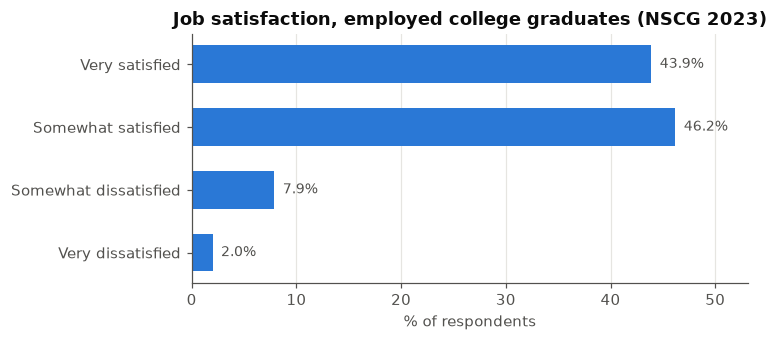

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(dist.index, dist['unweighted %'], color=BLUE, height=0.6)
for y, v in enumerate(dist['unweighted %']):
    ax.text(v + 0.8, y, f'{v:.1f}%', va='center', color=TEXT2, fontsize=9)
ax.set_title('Job satisfaction, employed college graduates (NSCG 2023)')
ax.set_xlabel('% of respondents'); ax.grid(axis='y', visible=False)
ax.set_xlim(0, dist['unweighted %'].max() * 1.15)
plt.tight_layout(); plt.show()

In [11]:
balance = df['satisfied'].value_counts().rename({1: 'satisfied', 0: 'not satisfied'})
print(balance.to_string())
print(f"Share satisfied: {df['satisfied'].mean():.1%} unweighted, "
      f"{np.average(df['satisfied'], weights=df['WTSURVY']):.1%} weighted")

satisfied
satisfied        71919
not satisfied     7881
Share satisfied: 90.1% unweighted, 89.9% weighted


**Observation:** The binary target is heavily imbalanced, roughly 9 satisfied for every 1 not satisfied. A model that always predicts "satisfied" would get ~90% accuracy, so accuracy is not a useful metric here. This supports the October milestone's plan (issue #10) to use AUC, precision/recall/F1 and class weighting or stratified splits. An alternative target is "very satisfied" vs. the rest, which is closer to 45/55.

## 6. Missing values and special codes

NSCG never leaves a cell blank for a skipped question; it uses codes. Within the analysis sample we convert these to `NaN`:
- `L` = logical skip (question did not apply); `E` / `M` = erroneously missing / missing in Yes-No questions (careful: `M` in `SEX_2023` means Male)
- `9999998` in `SALARY` = logical skip
- `98` in `HRSWK` = logical skip

In [12]:
SKIP = {'L', 'E', '9999998', ''}
clean = df.copy()
for c in BASELINE + FAC + SAT + OCC:
    clean[c] = clean[c].where(~clean[c].isin(SKIP))
# "M" means Missing only in Yes/No questions; in SEX_2023 it means Male
for c in ['SUPWK', 'MARIND']:
    clean[c] = clean[c].where(clean[c] != 'M')
clean.loc[clean['HRSWK'] == '98', 'HRSWK'] = np.nan
clean.loc[clean['N3OCPR'] == '999989', 'N3OCPR'] = np.nan   # 999989 = logical skip for occupation

missing = (clean[BASELINE + FAC + SAT + OCC].isna().mean() * 100).round(2).sort_values(ascending=False)
missing.rename('missing %').to_frame().head(15)

,missing %
SALARY,0.0
HRSWK,0.0
AGE,0.0
SEX_2023,0.0
RACETHM,0.0
DGRDG,0.0
EMSECSM,0.0
EMSIZE,0.0
OCEDRLP,0.0
SUPWK,0.0


**Observation:** After filtering to employed respondents, missingness is close to zero for nearly every variable. NSCG imputes item non-response before releasing the public file, so there is little cleaning to do and **no need to impute the target**. This is a big advantage over GSS, where many people have no satisfaction answer.

## 7. Baseline features

### 7.1 Numeric: salary, hours, age

In [13]:
for c in ['SALARY', 'HRSWK', 'AGE']:
    clean[c] = pd.to_numeric(clean[c])
clean[['SALARY', 'HRSWK', 'AGE']].describe().round(1)

,SALARY,HRSWK,AGE
count,79800.0,79800.0,79800.0
mean,109414.2,40.9,41.9
std,88989.5,11.0,13.0
min,0.0,1.0,19.0
25%,60000.0,40.0,31.0
50%,94500.0,40.0,39.0
75%,138500.0,45.0,52.0
max,976934.0,96.0,75.0


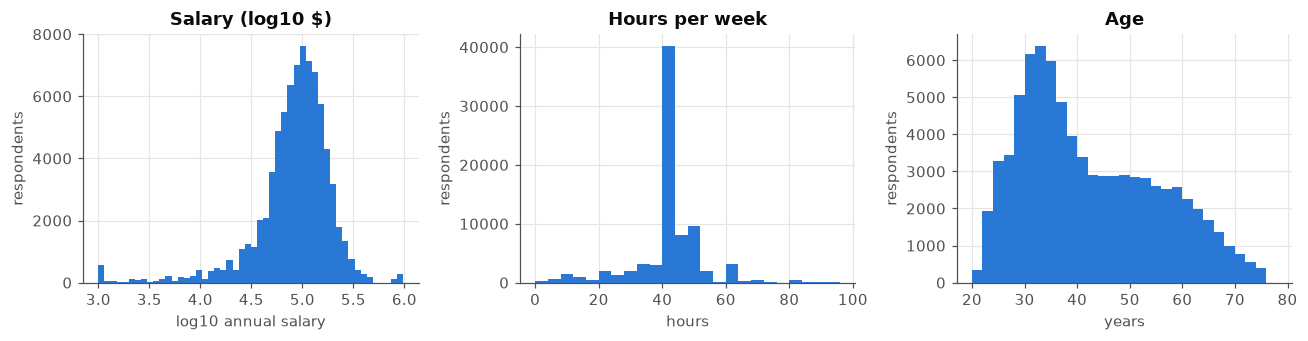

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].hist(np.log10(clean['SALARY'].clip(lower=1000)), bins=50, color=BLUE)
axes[0].set_title('Salary (log10 $)'); axes[0].set_xlabel('log10 annual salary')
axes[1].hist(clean['HRSWK'], bins=range(0, 100, 4), color=BLUE)
axes[1].set_title('Hours per week'); axes[1].set_xlabel('hours')
axes[2].hist(clean['AGE'], bins=range(20, 80, 2), color=BLUE)
axes[2].set_title('Age'); axes[2].set_xlabel('years')
for ax in axes: ax.set_ylabel('respondents')
plt.tight_layout(); plt.show()

**Observation:** Salary is strongly right-skewed (top-coded at the high end in the public file), so a log transform is appropriate for modeling. Hours cluster at 40 with a long tail of 50-60+ hour weeks. Ages range from early 20s to mid 70s.

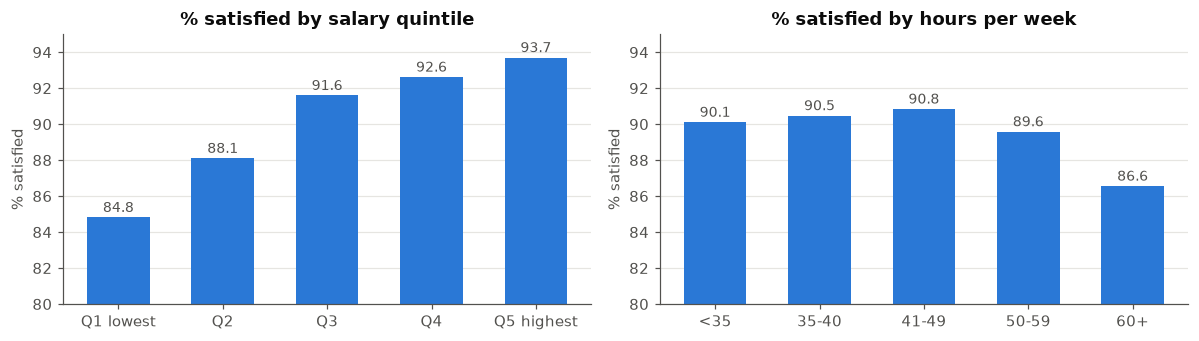

In [14]:
# Satisfaction rate across salary and hours bands
clean['salary_band'] = pd.qcut(clean['SALARY'], 5, labels=['Q1 lowest', 'Q2', 'Q3', 'Q4', 'Q5 highest'])
clean['hours_band'] = pd.cut(clean['HRSWK'], [0, 34, 40, 49, 59, 100],
                             labels=['<35', '35-40', '41-49', '50-59', '60+'])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, col, title in [(axes[0], 'salary_band', 'Salary quintile'), (axes[1], 'hours_band', 'Hours per week')]:
    rate = clean.groupby(col, observed=True)['satisfied'].mean() * 100
    ax.bar(rate.index.astype(str), rate.values, color=BLUE, width=0.6)
    for x, v in enumerate(rate.values):
        ax.text(x, v + 0.3, f'{v:.1f}', ha='center', color=TEXT2, fontsize=9)
    ax.set_ylim(80, 95); ax.set_title(f'% satisfied by {title.lower()}'); ax.set_ylabel('% satisfied')
    ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

### 7.2 Categorical features

In [15]:
CATEGORICAL = ['SEX_2023', 'RACETHM', 'DGRDG', 'EMSECSM', 'EMSIZE', 'OCEDRLP', 'SUPWK', 'MARIND']

def sat_by(col):
    t = (clean.assign(group=clean[col].map(labels_for(col)).fillna(clean[col]))
              .groupby('group')
              .agg(n=('satisfied', 'size'), pct_satisfied=('satisfied', 'mean')))
    t['pct_of_sample'] = (t['n'] / t['n'].sum() * 100).round(1)
    t['pct_satisfied'] = (t['pct_satisfied'] * 100).round(1)
    return t.sort_values('pct_satisfied')

for c in CATEGORICAL:
    print(f"\n{c}: {dictionary.set_index('SAS_NAME').at[c, 'DESCRIPTION']}")
    display(sat_by(c))


SEX_2023: Sex at birth


,n,pct_satisfied,pct_of_sample
group,,,
Female,36463,89.5,45.7
Male,43337,90.7,54.3



RACETHM: Race/ethnicity


,n,pct_satisfied,pct_of_sample
group,,,
"Native Hawaiian/Other Pacific Islander, non-Hispanic ONLY",91,85.7,0.1
"Black, non-Hispanic ONLY",6430,86.5,8.1
"Multiple Race, non-Hispanic",2801,87.5,3.5
"American Indian/Alaska Native, non-Hispanic ONLY",239,88.7,0.3
"Hispanic, any race",10941,89.4,13.7
"Asian, non-Hispanic ONLY",15738,89.9,19.7
"White, non-Hispanic ONLY",43560,91.1,54.6



DGRDG: Highest degree type


...

,n,pct_satisfied,pct_of_sample
group,,,
Not related,10762,82.6,13.5
Somewhat related,19970,88.8,25.0
Closely related,49068,92.3,61.5



SUPWK: Supervised others in principal job indicator


,n,pct_satisfied,pct_of_sample
group,,,
No,47429,89.1,59.4
Yes,32371,91.6,40.6



MARIND: Marital status indicator


,n,pct_satisfied,pct_of_sample
group,,,
No,29044,86.8,36.4
Yes,50756,92.0,63.6


**Observation:** The largest gaps are degree relatedness (`OCEDRLP`: 92.3% satisfied when closely related vs 82.6% when not related), marital status (92.0% vs 86.8%) and supervising others (91.6% vs 89.1%). Race/ethnicity, degree level, sector and employer size differ by only a few points. Some groups are very small (Native Hawaiian/Pacific Islander n=91, American Indian/Alaska Native n=239), so their rates are unstable and may need to be merged for modeling. `OCEDRLP` (how related the job is to one's degree) is itself a crude fit measure, so it should be discussed as to whether it belongs in the baseline or the fit feature set.

## 8. Work values and facet satisfaction

This is what makes NSCG valuable for the project. Each respondent rates how **important** 9 job aspects are to them (`FAC*`, their personal work values), and how **satisfied** they are with the same 9 aspects in their current job (`SAT*`).

### 8.1 How important is each aspect?

In [16]:
IMPORTANCE = {'1': 4, '2': 3, '3': 2, '4': 1}   # 4 = very important ... 1 = not important at all
SATISFACTION = {'1': 4, '2': 3, '3': 2, '4': 1}  # 4 = very satisfied ... 1 = very dissatisfied
for a in ASPECTS:
    clean[f'imp_{a}'] = clean[f'FAC{a}'].map(IMPORTANCE)
    clean[f'sat_{a}'] = clean[f'SAT{a}'].map(SATISFACTION)

imp = pd.DataFrame({
    '% very important': [(clean[f'imp_{a}'] == 4).mean() * 100 for a in ASPECTS],
    '% satisfied with it in current job': [(clean[f'sat_{a}'] >= 3).mean() * 100 for a in ASPECTS],
}, index=ASPECTS.values()).round(1).sort_values('% very important')
imp

,% very important,% satisfied with it in current job
Responsibility,41.3,89.6
Advancement,47.6,71.6
Contribution to society,50.3,87.8
Intellectual challenge,57.1,85.8
Independence,63.2,92.6
Location,64.1,90.0
Job security,71.3,88.2
Benefits,74.9,82.0
Salary,76.4,78.4


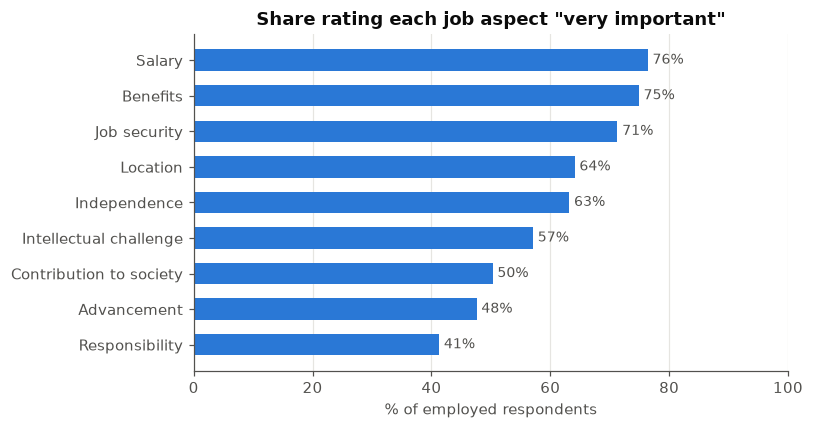

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(imp.index, imp['% very important'], color=BLUE, height=0.6)
for y, v in enumerate(imp['% very important']):
    ax.text(v + 0.8, y, f'{v:.0f}%', va='center', color=TEXT2, fontsize=9)
ax.set_title('Share rating each job aspect "very important"')
ax.set_xlabel('% of employed respondents'); ax.set_xlim(0, 100); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

### 8.2 Which facets move overall satisfaction?

In [18]:
# Spearman correlation of each facet's satisfaction and importance with overall job satisfaction
corr = pd.DataFrame({
    'facet satisfaction vs overall': [clean[f'sat_{a}'].corr(clean['job_satisfaction'], method='spearman') for a in ASPECTS],
    'importance vs overall': [clean[f'imp_{a}'].corr(clean['job_satisfaction'], method='spearman') for a in ASPECTS],
}, index=ASPECTS.values()).round(3).sort_values('facet satisfaction vs overall')
corr

,facet satisfaction vs overall,importance vs overall
Location,0.307,0.082
Benefits,0.375,0.009
Job security,0.387,0.078
Contribution to society,0.424,0.125
Independence,0.461,0.153
Salary,0.485,-0.011
Intellectual challenge,0.527,0.158
Advancement,0.533,-0.007
Responsibility,0.539,0.161


**Caution for modeling:** facet satisfaction (`SAT*`) correlates strongly with overall satisfaction because it is almost the same question. It should **not** be used as a predictor; that would be leakage. Importance ratings (`FAC*`) on their own barely predict satisfaction. Their value comes from comparing them with what the occupation offers, which is the person-job fit idea.

### 8.3 Preview of person-job fit

A first look at fit without O*NET: among people who rate an aspect as **very important**, does being satisfied with that aspect in their job go with higher overall satisfaction? Below, "fit" = rated very important and satisfied with it; "misfit" = rated very important but dissatisfied with it.

In [19]:
rows = []
for a, name in ASPECTS.items():
    cares = clean[clean[f'imp_{a}'] == 4]
    fit = cares[cares[f'sat_{a}'] >= 3]['satisfied'].mean() * 100
    misfit = cares[cares[f'sat_{a}'] <= 2]['satisfied'].mean() * 100
    rows.append({'aspect': name, 'n very important': len(cares),
                 '% satisfied: fit': round(fit, 1), '% satisfied: misfit': round(misfit, 1),
                 'gap (pts)': round(fit - misfit, 1)})
fit_preview = pd.DataFrame(rows).set_index('aspect').sort_values('gap (pts)')
fit_preview

,n very important,% satisfied: fit,% satisfied: misfit,gap (pts)
aspect,,,,
Benefits,59801,93.5,71.3,22.1
Location,51152,92.6,70.5,22.2
Salary,60972,95.6,68.3,27.3
Job security,56907,93.7,66.5,27.3
Advancement,37971,97.5,67.9,29.6
Intellectual challenge,45600,96.0,56.0,40.0
Contribution to society,40140,94.3,52.5,41.8
Independence,50461,94.0,51.8,42.2
Responsibility,32981,95.9,51.7,44.2


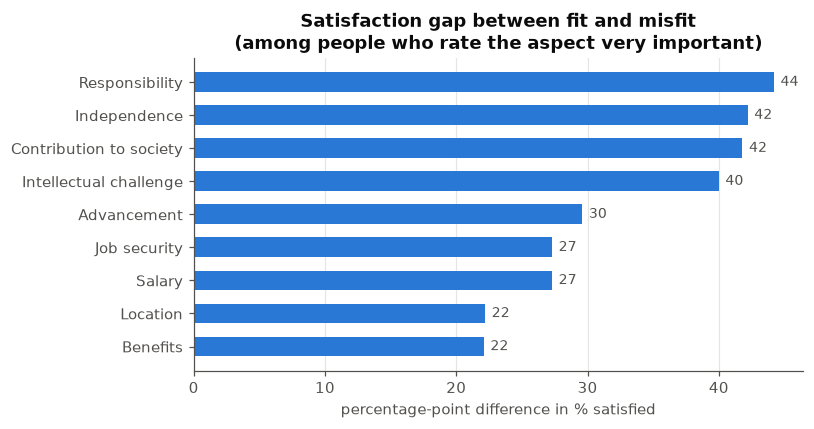

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(fit_preview.index, fit_preview['gap (pts)'], color=BLUE, height=0.6)
for y, v in enumerate(fit_preview['gap (pts)']):
    ax.text(v + 0.5, y, f'{v:.0f}', va='center', color=TEXT2, fontsize=9)
ax.set_title('Satisfaction gap between fit and misfit\n(among people who rate the aspect very important)')
ax.set_xlabel('percentage-point difference in % satisfied'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

**Observation:** This uses self-reported facet satisfaction, so it is an upper bound and not a model feature (see the caution above). It does show which aspects matter most when they go wrong, which is a guide for which O*NET work-value dimensions to prioritize when building fit scores.

## 9. Occupation codes and linkage to O*NET

`N3OCPR` is the respondent's principal job, coded with **NCSES's own 6-digit occupation codes** (e.g. `110590` = Software developers). These are **not SOC codes**, so they cannot be joined to O*NET directly.

In [21]:
occ_labels = labels_for('N3OCPR')
occ = (clean.assign(occupation=clean['N3OCPR'].map(occ_labels))
            .groupby(['N3OCPR', 'occupation'])
            .agg(n=('satisfied', 'size'), pct_satisfied=('satisfied', 'mean')))
occ['pct_satisfied'] = (occ['pct_satisfied'] * 100).round(1)
print(f'{len(occ)} distinct occupation codes; median {occ.n.median():.0f} respondents per code; '
      f'{(occ.n < 100).sum()} codes with fewer than 100 respondents')
occ.sort_values('n', ascending=False).head(15)

129 distinct occupation codes; median 371 respondents per code; 17 codes with fewer than 100 respondents


,,n,pct_satisfied
N3OCPR,occupation,,
110590,Software developers – applications and systems software,4069,91.5
611120,"Registered nurses, pharmacists, dieticians, therapists, physician assistants, nurse practitioners",4048,91.2
711410,"Top-executives (e.g., chief executives, general and operations managers, legislators)",3673,94.8
721530,Other management-related occupations,3381,90.2
711470,Other mid-level managers,2184,92.3
560940,Mechanical engineers,2106,91.6
721510,"Financial specialists (e.g., accountants, auditors)",2038,89.1
780330,Other office and administrative support workers,1955,82.3
540890,Electrical and electronics engineers,1916,92.6


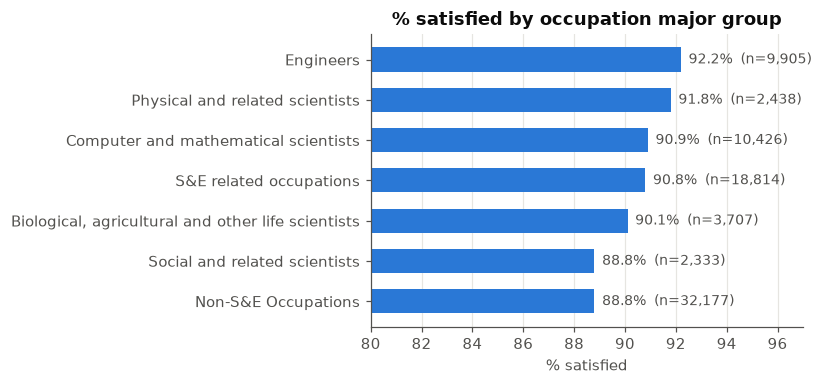

In [22]:
grp = sat_by('N2OCPRMG')
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(grp.index, grp['pct_satisfied'], color=BLUE, height=0.6)
for y, (v, n) in enumerate(zip(grp['pct_satisfied'], grp['n'])):
    ax.text(v + 0.3, y, f'{v:.1f}%  (n={n:,})', va='center', color=TEXT2, fontsize=9)
ax.set_xlim(80, 97); ax.set_title('% satisfied by occupation major group')
ax.set_xlabel('% satisfied'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

**Linkage plan:**
1. NCSES publishes a crosswalk from its occupation codes to SOC (search "SESTAT occupation codes SOC crosswalk" on ncses.nsf.gov). It is not part of the public-use zip and needs to be downloaded separately.
2. Many NSCG codes are **broader** than SOC detailed occupations (130 codes vs. 867 SOC detailed occupations), so one NSCG code will map to several SOC/O*NET occupations. O*NET profiles would need to be averaged across them (ideally weighted by employment).
3. The 2023 file uses updated codes (the README notes psychologists were split in 2023), so check the crosswalk matches the 2023 coding.

**Mapping NSCG work values to O*NET Work Values (30.2):**

| NSCG importance item | Closest O*NET Work Value / need |
|---|---|
| Advancement (`FACADV`) | Recognition (Advancement) |
| Salary (`FACSAL`), Benefits (`FACBEN`) | Working Conditions (Compensation) |
| Job security (`FACSEC`) | Working Conditions (Security) |
| Independence (`FACIND`) | Independence (Autonomy) |
| Responsibility (`FACRESP`) | Recognition (Authority) / Independence (Responsibility) |
| Intellectual challenge (`FACCHAL`) | Achievement (Ability Utilization) |
| Contribution to society (`FACSOC`) | Relationships (Social Service) |
| Location (`FACLOC`) | No O*NET equivalent |

This mapping needs to be checked against the O*NET Work Values element list with the team.

## 10. Save cleaned analysis file

In [23]:
keep = (['job_satisfaction', 'satisfied', 'WTSURVY', 'N3OCPR', 'N2OCPRMG'] + BASELINE
        + [f'imp_{a}' for a in ASPECTS] + [f'sat_{a}' for a in ASPECTS])
out = clean[keep].copy()
out.insert(4, 'occupation', out['N3OCPR'].map(occ_labels))
out_path = ROOT / 'data' / 'college_grads_2023' / 'nscg2023_clean.csv'
out.to_csv(out_path, index=False)
print(f'Saved {out.shape[0]:,} rows x {out.shape[1]} columns to {out_path.relative_to(ROOT)}')

Saved 79,800 rows x 35 columns to data\college_grads_2023\nscg2023_clean.csv


## 11. Next steps

1. Download the NCSES occupation-code-to-SOC crosswalk and join `N3OCPR` to SOC 2018, then to O*NET (using the crosswalk files already in `data/onet/`).
2. Agree with the team on the NSCG-to-O*NET work-value mapping in Section 9.
3. Decide the binary target cutoff (satisfied vs. not, or very satisfied vs. rest) together with the GSS and Gallup notebooks, so all datasets use a comparable definition.
4. Decide whether `OCEDRLP` (job related to degree) is a baseline feature or a fit feature.
5. Baseline models (October milestone): salary (log), hours, age, sex, race/ethnicity, degree, sector, employer size, supervisor, marital status; use AUC and class weighting given the 90/10 split.